In [1]:
df = read.csv("./Data_viem_tuy_cap.csv", header = TRUE)
head(df)

,X,STT,tho_may,Nam_sinh,tuoi,nghe_nghiep,gioi_tinh,dich_bu,can_nang,chieu_cao,⋯,sofa_2,apache_ii_2,Mor_thuc,Mor_du_doan_2,X.tg_giam,tg_giam,bisap_giam,apa_giam...187,apa_giam...188,apa_giam...189
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,⋯,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>
1,1,1,0,1986,37,1,1,2.352,49,150,⋯,4,6,0,NA,0.8761111,6308,2,13,NA,NA
2,2,2,0,1980,43,1,0,3.456,72,165,⋯,2,3,0,NA,0.7865535,1205,2,8,NA,NA
3,3,3,0,1986,37,1,0,3.840,80,173,⋯,7,12,0,NA,0.8670782,2107,1,12,NA,NA
4,4,4,0,1989,34,1,0,2.880,60,167,⋯,2,9,0,NA,0.9391941,2564,1,5,NA,NA
5,5,5,0,1964,59,3,0,2.640,55,168,⋯,8,23,0,NA,0.9445623,3561,0,10,NA,NA
6,6,6,0,1988,35,1,1,2.880,60,155,⋯,0,2,0,NA,0.9202761,3867,0,6,NA,NA


In [12]:
library(gtsummary)
library(dplyr)
library(gt)

# 2. Xử lý dữ liệu
df_bang <- df %>%
  mutate(
    nhom_tuoi = cut(
      tuoi,
      breaks = c(-Inf, 30, 40, 50, 60, Inf),
      labels = c("<= 30", "31-40", "41-50", "51-60", ">60"),
      right = TRUE
    )
  )

# 3. Tạo bảng thống kê mô tả (tổng thể và phân chia theo giới tính)
bang_mo_ta <- df_bang %>%
  select(tuoi, nhom_tuoi, gioi_tinh) %>%
  tbl_summary(
    by = gioi_tinh,                                    # Phân cột theo giới tính
    statistic = list(
      tuoi ~ "{mean} ± {sd}",                          # Tuổi định lượng: Mean ± SD
      nhom_tuoi ~ "{n} ({p}%)"                         # Nhóm tuổi định tính: n (%)
    ),
    digits = list(
      tuoi ~ c(2, 2),
      nhom_tuoi ~ c(0, 1)
    ),
    label = list(
      tuoi ~ "Tuổi trung bình (năm)",
      nhom_tuoi ~ "Phân nhóm tuổi"
    ),
    missing = "no"
  ) %>%
  add_overall(last = FALSE, col_label = "**Chung** (N = {N})") %>% # Thêm cột Chung
  modify_header(label = "**Đặc điểm**") %>%
  bold_labels()

# Hiển thị bảng
as_kable(bang_mo_ta)

Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”
Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”




|**Đặc điểm**              | **Chung** (N = 93) | **0**  N = 64 | **1**  N = 29 |
|:-------------------------|:------------------:|:-------------:|:-------------:|
|__Tuổi trung bình (năm)__ |    41.81 ± 8.64    | 41.91 ± 7.91  | 41.59 ± 10.24 |
|__Phân nhóm tuổi__        |                    |               |               |
|<= 30                     |      9 (9.7%)      |   4 (6.3%)    |   5 (17.2%)   |
|31-40                     |     32 (34.4%)     |  25 (39.1%)   |   7 (24.1%)   |
|41-50                     |     39 (41.9%)     |  25 (39.1%)   |  14 (48.3%)   |
|51-60                     |     12 (12.9%)     |  10 (15.6%)   |   2 (6.9%)    |
|>60                       |      1 (1.1%)      |   0 (0.0%)    |   1 (3.4%)    |

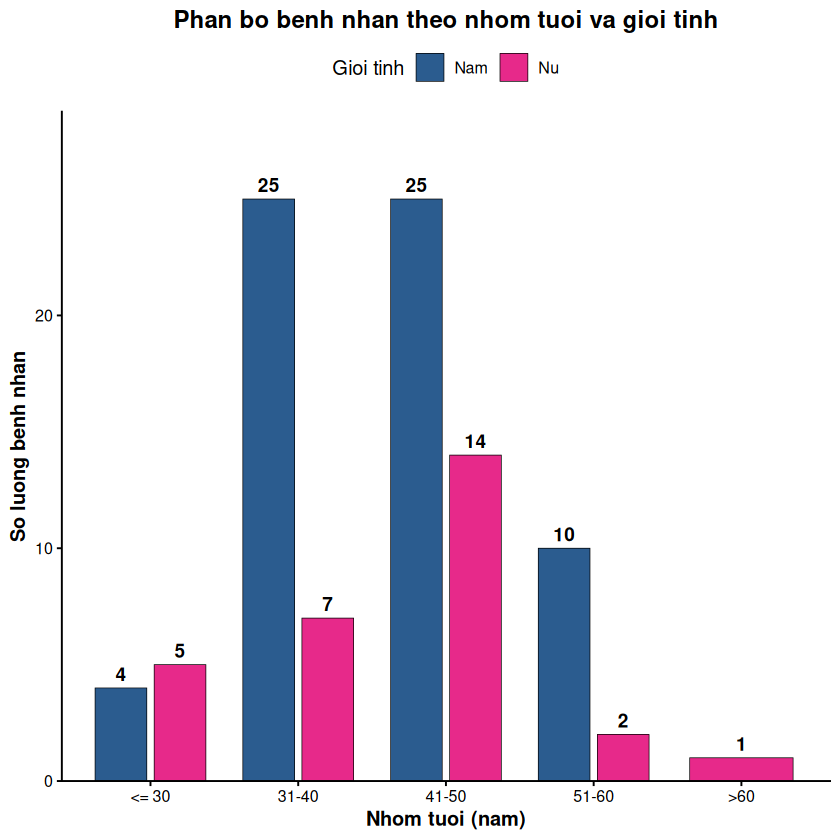

In [ ]:
library(dplyr)
library(ggplot2)

# 1. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 2. Xử lý nhóm tuổi và gán nhãn giới tính (0: Nam, 1: Nu)
df <- df %>%
  mutate(
    nhom_tuoi = cut(
      tuoi,
      breaks = c(-Inf, 30, 40, 50, 60, Inf),
      labels = c("<= 30", "31-40", "41-50", "51-60", ">60"),
      right = TRUE
    ),
    gioi_tinh = factor(gioi_tinh, levels = c(0, 1), labels = c("Nam", "Nu"))
  )

# 3. Tính tần số theo nhóm tuổi và giới tính
df_summary <- df %>%
  count(nhom_tuoi, gioi_tinh)

# 4. Vẽ biểu đồ cột
p1 <- ggplot(df_summary, aes(x = nhom_tuoi, y = n, fill = gioi_tinh)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.7, color = "black", linewidth = 0.2) +
  geom_text(
    aes(label = n),
    position = position_dodge(width = 0.8),
    vjust = -0.5,
    size = 4,
    fontface = "bold"
  ) +
  scale_fill_manual(
    values = c("Nam" = "#2b5c8f", "Nu" = "#e7298a"),
    name = "Gioi tinh"
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(
    title = "Phan bo benh nhan theo nhom tuoi va gioi tinh",
    x = "Nhom tuoi",
    y = "So luong benh nhan"
  ) +
  theme_classic(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.title = element_text(face = "bold"),
    legend.position = "top"
  )

# Hiển thị biểu đồ
p1

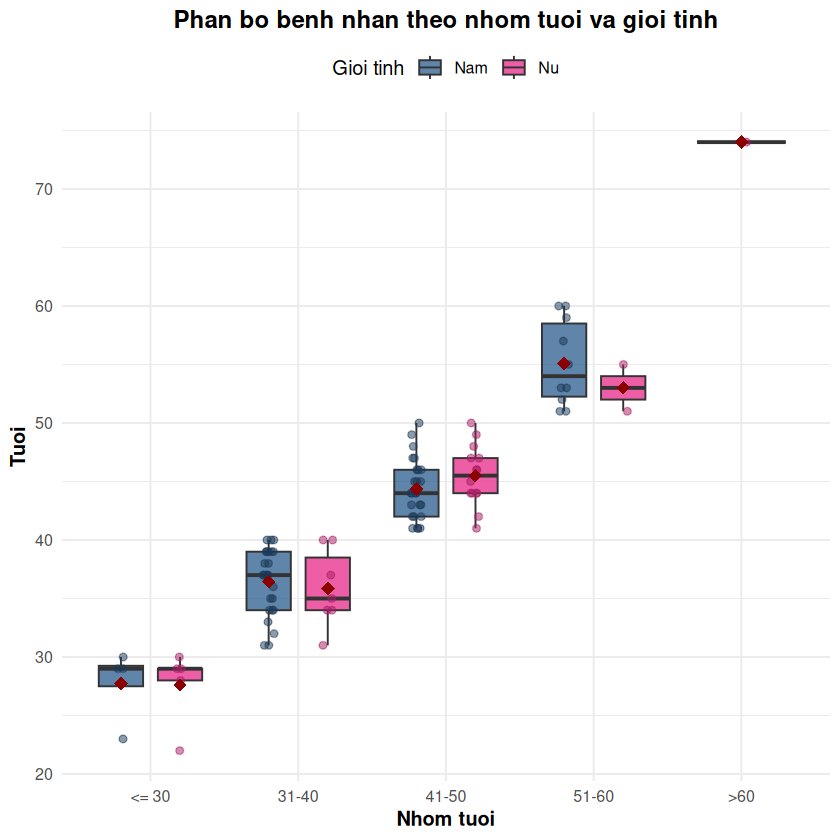

In [22]:
p2 <- ggplot(df, aes(x = nhom_tuoi, y = tuoi, fill = gioi_tinh)) +
  geom_boxplot(
    position = position_dodge(width = 0.8),
    width = 0.6,
    alpha = 0.75,
    outlier.shape = NA
  ) +
  geom_point(
    position = position_jitterdodge(jitter.width = 0.15, dodge.width = 0.8),
    alpha = 0.5,
    size = 1.8,
    aes(color = gioi_tinh),
    show.legend = FALSE
  ) +
  # Thêm điểm biểu diễn giá trị Trung bình (Mean)
  stat_summary(
    fun = mean,
    geom = "point",
    shape = 18,
    size = 3.5,
    color = "darkred",
    position = position_dodge(width = 0.8),
    show.legend = FALSE
  ) +
  scale_fill_manual(values = c("Nam" = "#2b5c8f", "Nu" = "#e7298a"), name = "Gioi tinh") +
  scale_color_manual(values = c("Nam" = "#1a3857", "Nu" = "#a81d64")) +
  labs(
    title = "Phan bo benh nhan theo nhom tuoi va gioi tinh",
    x = "Nhom tuoi",
    y = "Tuoi"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5, face = "italic"),
    axis.title = element_text(face = "bold"),
    legend.position = "top"
  )

# Hiển thị biểu đồ
p2

In [30]:
# 1. Nạp các thư viện cần thiết
library(dplyr)
library(gtsummary)
library(knitr)
# library(gt) # Mở nếu muốn dùng as_gt()

# 2. Đọc file dữ liệu (nếu chưa nạp vào R)
df <- read.csv("Data_viem_tuy_cap.csv")

# 3. Chuẩn hóa và gán nhãn cho các biến
df_bang <- df %>%
  # Loại bỏ các dòng khuyết giới tính (nếu có) để tránh cảnh báo missing rows
  filter(!is.na(gioi_tinh)) %>%
  mutate(
    # Mã hóa biến phân nhóm Giới tính
    gioi_tinh = factor(gioi_tinh, levels = c(0, 1), labels = c("Nam", "Nữ")),
        # Mã hóa các biến tiền căn bệnh lý (0: Không, 1: Có)
    dtd         = factor(dtd, levels = c(0, 1), labels = c("Không", "Có")),
    tha         = factor(tha, levels = c(0, 1), labels = c("Không", "Có")),
    nghien_ruou = factor(nghien_ruou, levels = c(0, 1), labels = c("Không", "Có")),
    tien_su_vtc = factor(tien_su_vtc, levels = c(0, 1), labels = c("Không", "Có"))
  )

# 4. Lập bảng thống kê mô tả bằng gtsummary
bang_mo_ta <- df_bang %>%
  select(dtd, tha, nghien_ruou, tien_su_vtc, gioi_tinh) %>%
  tbl_summary(
    by = gioi_tinh,                                    # Phân cột theo Giới tính
    label = list(
      dtd         ~ "Tiền căn đái tháo đường",
      tha         ~ "Tăng huyết áp",
      nghien_ruou ~ "Tiền căn nghiện rượu",
      tien_su_vtc ~ "Tiền căn viêm tụy cấp"
    ),
    missing = "no"                                     # Không hiển thị dòng đếm khuyết tật
  ) %>%
  add_overall(last = FALSE, col_label = "**Chung** (N = {N})") %>% # Thêm cột Tổng cộng
  modify_header(label = "**Đặc điểm**") %>%
  bold_labels()

# 5. Hiển thị bảng trong Jupyter Notebook
as_kable(bang_mo_ta)

Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”
Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”




|**Đặc điểm**                | **Chung** (N = 93) | **Nam**  N = 64 | **Nữ**  N = 29 |
|:---------------------------|:------------------:|:---------------:|:--------------:|
|__Tiền căn đái tháo đường__ |                    |                 |                |
|Không                       |      40 (43%)      |    28 (44%)     |    12 (41%)    |
|Có                          |      53 (57%)      |    36 (56%)     |    17 (59%)    |
|__Tăng huyết áp__           |                    |                 |                |
|Không                       |      73 (78%)      |    52 (81%)     |    21 (72%)    |
|Có                          |      20 (22%)      |    12 (19%)     |    8 (28%)     |
|__Tiền căn nghiện rượu__    |                    |                 |                |
|Không                       |      78 (84%)      |    49 (77%)     |   29 (100%)    |
|Có                          |      15 (16%)      |    15 (23%)     |     0 (0%)     |
|__Tiền căn viêm tụy cấp__   |           

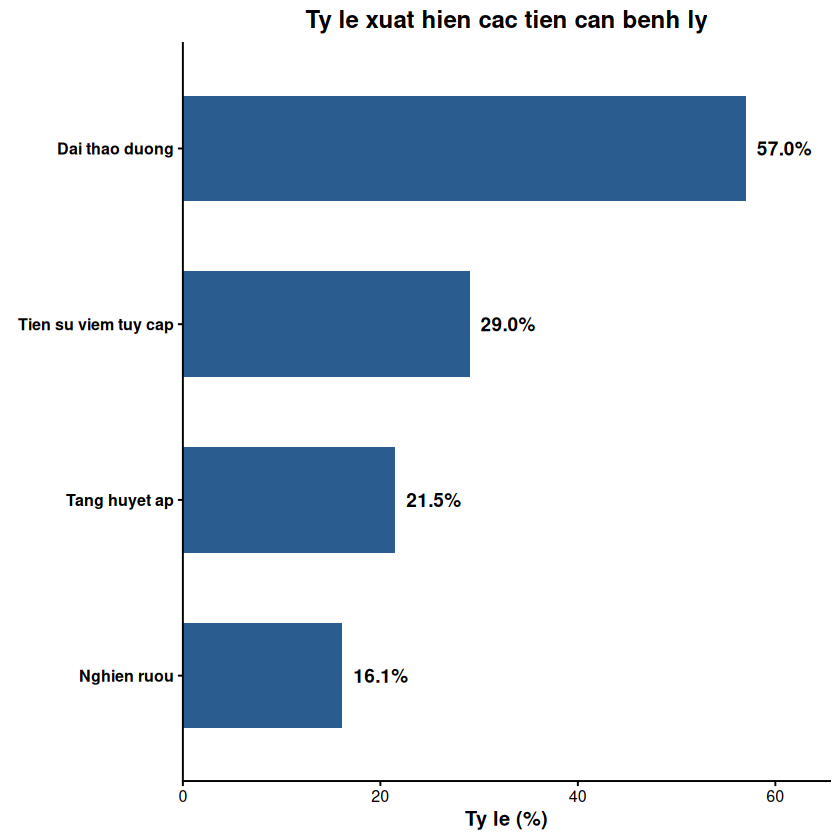

In [29]:
library(dplyr)
library(tidyr)
library(ggplot2)

# 1. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 2. Tính tỷ lệ % xuất hiện (giá trị = 1) cho từng bệnh lý
df_benh_ly <- df %>%
  summarise(
    "Tang huyet ap"           = mean(tha == 1, na.rm = TRUE) * 100,
    "Nghien ruou"             = mean(nghien_ruou == 1, na.rm = TRUE) * 100,
    "Dai thao duong"          = mean(dtd == 1, na.rm = TRUE) * 100,
    "Tien su viem tuy cap"    = mean(tien_su_vtc == 1, na.rm = TRUE) * 100
  ) %>%
  pivot_longer(
    cols = everything(),
    names_to = "Benh_ly",
    values_to = "Ty_le"
  )

# 3. Vẽ biểu đồ thanh ngang
p1 <- ggplot(df_benh_ly, aes(x = Ty_le, y = reorder(Benh_ly, Ty_le))) +
  geom_col(fill = "#2b5c8f", width = 0.6) +
  geom_text(
    aes(label = sprintf("%.1f%%", Ty_le)),
    hjust = -0.2,
    size = 4,
    fontface = "bold"
  ) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(
    title = "Ty le xuat hien cac tien can benh ly",
    x = "Ty le (%)",
    y = NULL
  ) +
  theme_classic(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.title.x = element_text(face = "bold"),
    axis.text.y = element_text(face = "bold", color = "black")
  )

p1

In [31]:
library(dplyr)
library(gtsummary)
library(knitr)

df_bang <- df %>%
  filter(!is.na(gioi_tinh)) %>%
  mutate(
    # Gán nhãn giới tính (0: Nam, 1: Nữ)
    gioi_tinh = factor(gioi_tinh, levels = c(0, 1), labels = c("Nam", "Nữ")),
    
    # Phân nhóm BMI bằng case_when
    bmig = case_when(
      bmi < 18.5              ~ "Underweight",
      bmi >= 18.5 & bmi < 24.9 ~ "Normal",
      bmi >= 24.9 & bmi < 29.9 ~ "Overweight",
      bmi >= 29.9             ~ "Obese"
    ),
    bmig = factor(bmig, levels = c("Underweight", "Normal", "Overweight", "Obese"))
  )

# Lập bảng thống kê phân nhóm BMI theo giới tính
bang_bmi <- df_bang %>%
  select(bmig, gioi_tinh) %>%
  tbl_summary(
    by = gioi_tinh,
    statistic = all_categorical() ~ "{n} ({p}%)",
    digits = all_categorical() ~ c(0, 1),
    label = list(bmig ~ "Phân loại BMI"),
    missing = "no"
  ) %>%
  add_overall(last = FALSE, col_label = "**Chung** (N = {N})") %>%
  bold_labels()

# Hiển thị bảng
as_kable(bang_bmi)

Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”
Warning message:
“'xfun::attr()' is deprecated.
Use 'xfun::attr2()' instead.
See help("Deprecated")”




|**Characteristic** | **Chung** (N = 93) | **Nam**  N = 64 | **Nữ**  N = 29 |
|:------------------|:------------------:|:---------------:|:--------------:|
|__Phân loại BMI__  |                    |                 |                |
|Underweight        |      2 (2.2%)      |    1 (1.6%)     |    1 (3.4%)    |
|Normal             |     48 (51.6%)     |   29 (45.3%)    |   19 (65.5%)   |
|Overweight         |     32 (34.4%)     |   26 (40.6%)    |   6 (20.7%)    |
|Obese              |     11 (11.8%)     |    8 (12.5%)    |   3 (10.3%)    |

In [33]:
library(dplyr)
library(ggplot2)

# 1. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 2. Tiền xử lý dữ liệu
df_plot <- df %>%
  filter(!is.na(gioi_tinh) & !is.na(bmi)) %>%
  mutate(
    # Gán nhãn giới tính
    gioi_tinh = factor(gioi_tinh, levels = c(0, 1), labels = c("Nam", "Nu")),
    
    # Phân nhóm BMI
    bmig = case_when(
      bmi < 18.5               ~ "Underweight",
      bmi >= 18.5 & bmi < 24.9 ~ "Normal",
      bmi >= 24.9 & bmi < 29.9 ~ "Overweight",
      bmi >= 29.9              ~ "Obese"
    ),
    # Cố định thứ tự hiển thị của các nhóm BMI
    bmig = factor(bmig, levels = c("Underweight", "Normal", "Overweight", "Obese"))
  )

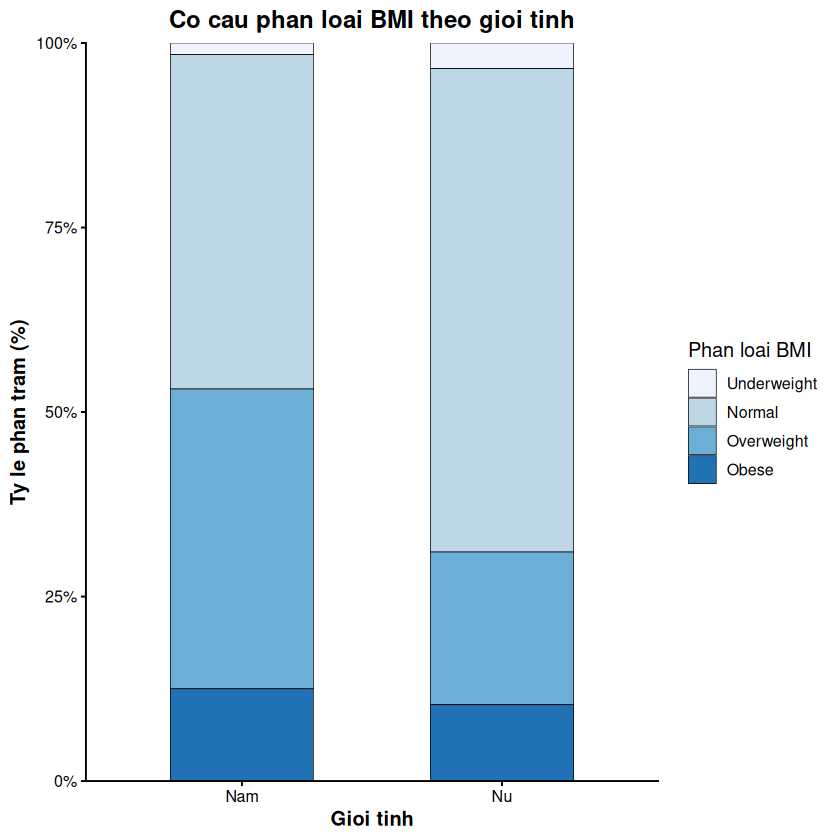

In [35]:
p2 <- ggplot(df_plot, aes(x = gioi_tinh, fill = bmig)) +
  geom_bar(position = "fill", width = 0.55, color = "black", linewidth = 0.2) +
  scale_y_continuous(labels = scales::percent_format(), expand = c(0, 0)) +
  scale_fill_brewer(palette = "Blues", name = "Phan loai BMI") +
  labs(
    title = "Co cau phan loai BMI theo gioi tinh",
    x = "Gioi tinh",
    y = "Ty le phan tram (%)"
  ) +
  theme_classic(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.title = element_text(face = "bold"),
    axis.text = element_text(color = "black"),
    legend.position = "right"
  )

p2

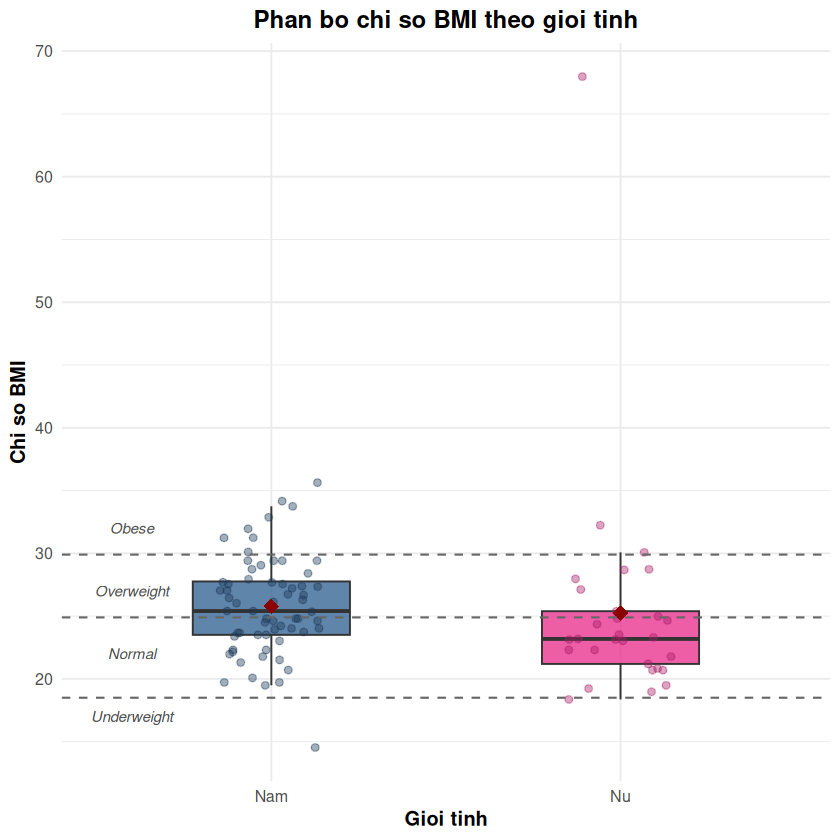

In [37]:
p3 <- ggplot(df_plot, aes(x = gioi_tinh, y = bmi, fill = gioi_tinh)) +
  geom_boxplot(width = 0.45, alpha = 0.75, outlier.shape = NA) +
  geom_jitter(width = 0.15, alpha = 0.4, size = 1.8, aes(color = gioi_tinh), show.legend = FALSE) +
  # Thêm điểm Trung bình (Mean)
  stat_summary(fun = mean, geom = "point", shape = 18, size = 4, color = "darkred") +
  # Vẽ các đường ranh giới phân loại BMI tham chiếu
  geom_hline(yintercept = c(18.5, 24.9, 29.9), linetype = "dashed", color = "gray40", linewidth = 0.6) +
  annotate("text", x = 0.6, y = 17, label = "Underweight", size = 3.2, fontface = "italic", color = "gray30") +
  annotate("text", x = 0.6, y = 22, label = "Normal", size = 3.2, fontface = "italic", color = "gray30") +
  annotate("text", x = 0.6, y = 27, label = "Overweight", size = 3.2, fontface = "italic", color = "gray30") +
  annotate("text", x = 0.6, y = 32, label = "Obese", size = 3.2, fontface = "italic", color = "gray30") +
  scale_fill_manual(values = c("Nam" = "#2b5c8f", "Nu" = "#e7298a")) +
  scale_color_manual(values = c("Nam" = "#1a3857", "Nu" = "#a81d64")) +
  labs(
    title = "Phan bo chi so BMI theo gioi tinh",
    x = "Gioi tinh",
    y = "Chi so BMI"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5, face = "italic"),
    axis.title = element_text(face = "bold"),
    legend.position = "none"
  )

p3

In [38]:
library(dplyr)

# 1. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 2. Xử lý và tính tần số, tỷ lệ %
thong_ke_atlanta <- df %>%
  # Loại bỏ giá trị khuyết NA nếu có
  filter(!is.na(Atlanta_0)) %>%
  mutate(
    Atlanta_0 = factor(
      Atlanta_0,
      levels = c(1, 2, 3),
      labels = c("VTC nhẹ", "VTC trung bình - nặng", "VTC nặng")
    )
  ) %>%
  count(Atlanta_0, name = "Tan_so") %>%
  mutate(
    Ty_le = round(Tan_so / sum(Tan_so) * 100, 2),
    Mo_ta = sprintf("%d (%.2f%%)", Tan_so, Ty_le)
  )

# In kết quả
print(thong_ke_atlanta)

              Atlanta_0 Tan_so Ty_le       Mo_ta
1               VTC nhẹ     43 46.24 43 (46.24%)
2 VTC trung bình - nặng     35 37.63 35 (37.63%)
3              VTC nặng     12 12.90 12 (12.90%)
4                  <NA>      3  3.23   3 (3.23%)


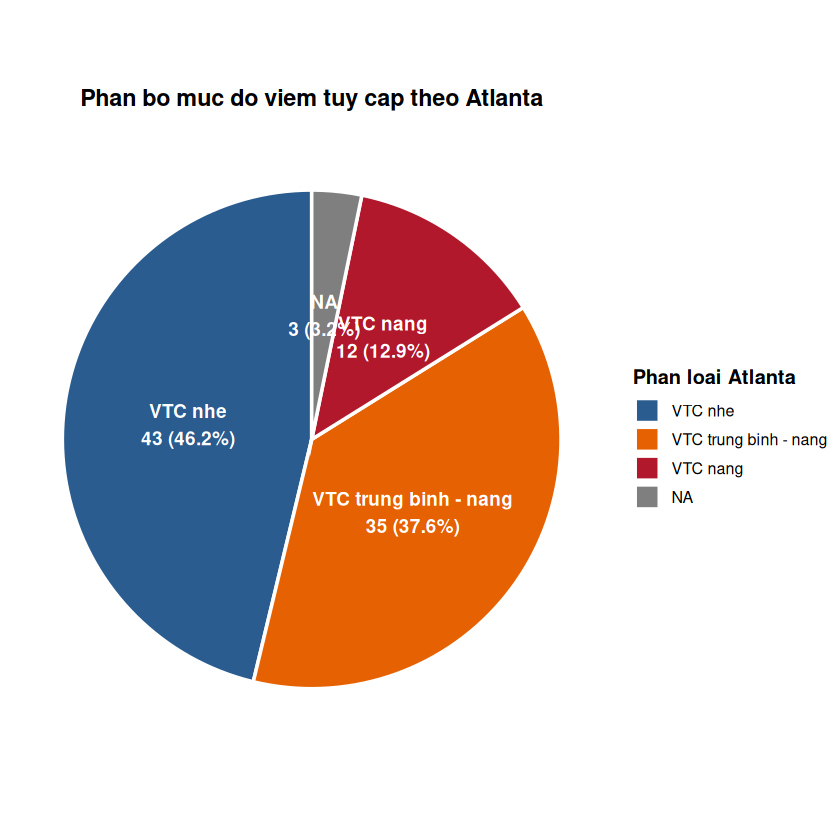

In [41]:
library(dplyr)
library(ggplot2)

# 1. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 2. Xử lý dữ liệu và tính toán tỷ lệ %
df_pie <- df %>%
  filter(!is.na(Atlanta_0)) %>%
  mutate(
    Atlanta_0 = factor(
      Atlanta_0,
      levels = c(1, 2, 3),
      labels = c("VTC nhe", "VTC trung binh - nang", "VTC nang")
    )
  ) %>%
  count(Atlanta_0, name = "n") %>%
  mutate(
    pct = n / sum(n) * 100,
    # Tạo nhãn gồm số ca và tỷ lệ %
    label = sprintf("%s\n%d (%.1f%%)", Atlanta_0, n, pct)
  )

# 3. Vẽ biểu đồ tròn (Pie chart)
p_pie <- ggplot(df_pie, aes(x = "", y = pct, fill = Atlanta_0)) +
  geom_col(width = 1, color = "white", linewidth = 1) +
  coord_polar(theta = "y", start = 0) +
  # Đặt nhãn vào chính giữa từng phần của hình tròn
  geom_text(
    aes(label = label),
    position = position_stack(vjust = 0.5),
    size = 4,
    fontface = "bold",
    color = "white"
  ) +
  scale_fill_manual(
    values = c(
      "VTC nhe" = "#2b5c8f", 
      "VTC trung binh - nang" = "#e66101", 
      "VTC nang" = "#b2182b"
    ),
    name = "Phan loai Atlanta"
  ) +
  labs(
    title = "Phan bo muc do viem tuy cap theo Atlanta",
    x = NULL,
    y = NULL
  ) +
  theme_void(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 14, margin = margin(b = 10)),
    legend.position = "right",
    legend.title = element_text(face = "bold")
  )

# Hiển thị biểu đồ
p_pie

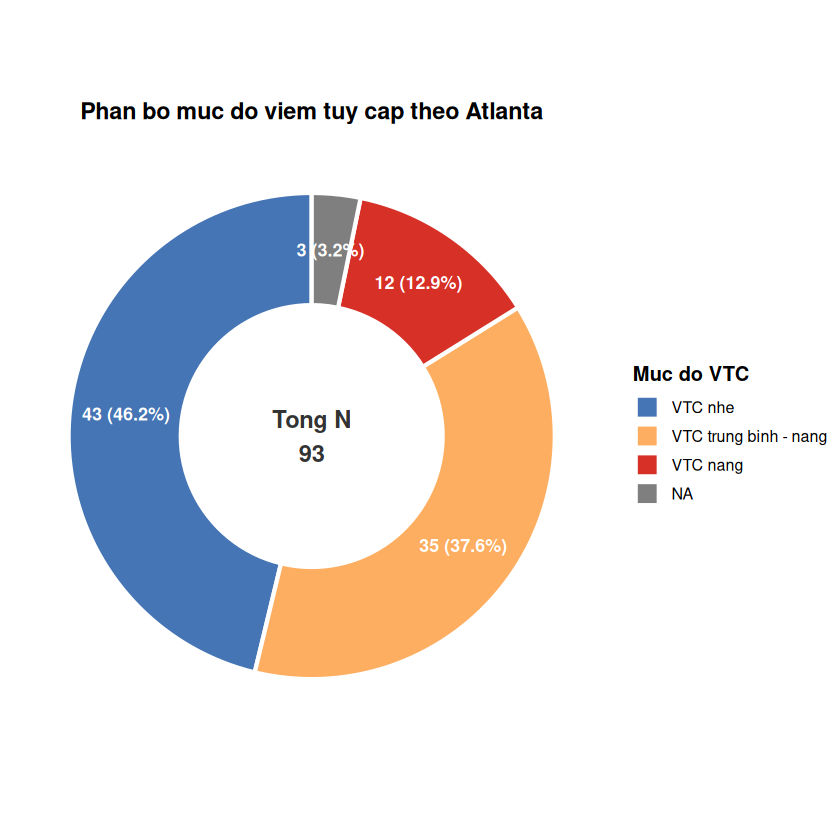

In [43]:
# Biến đổi thành Donut Chart bằng cách đặt x = 2 và giới hạn xlim
p_donut <- ggplot(df_pie, aes(x = 2, y = pct, fill = Atlanta_0)) +
  geom_col(color = "white", linewidth = 1.2) +
  coord_polar(theta = "y", start = 0) +
  xlim(0.5, 2.5) +  # Tạo lỗ tròn ở giữa
  geom_text(
    aes(label = sprintf("%d (%.1f%%)", n, pct)),
    position = position_stack(vjust = 0.5),
    size = 3.8,
    fontface = "bold",
    color = "white"
  ) +
  # Chèn tổng số ca vào tâm hình tròn
  annotate("text", x = 0.5, y = 0, label = paste0("Tong N\n", sum(df_pie$n)), 
           size = 5, fontface = "bold", color = "gray20") +
  scale_fill_manual(
    values = c(
      "VTC nhe" = "#4575b4", 
      "VTC trung binh - nang" = "#fdae61", 
      "VTC nang" = "#d73027"
    ),
    name = "Muc do VTC"
  ) +
  labs(title = "Phan bo muc do viem tuy cap theo Atlanta") +
  theme_void(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 14),
    legend.position = "right",
    legend.title = element_text(face = "bold")
  )

p_donut

In [45]:
# 1. Chuyển sang vector số
gio <- as.numeric(df$gio_khoi_phat[!is.na(df$gio_khoi_phat)])

# 2. Thống kê chung
cat(sprintf("Chung: Mean ± SD = %.2f ± %.2f | Min - Max = %.1f - %.1f\n\n",
            mean(gio), sd(gio), min(gio), max(gio)))

# 3. Phân nhóm và đếm tần số, %
nhom <- cut(gio, breaks = c(-Inf, 5.99, 12, 24, 48, Inf),
            labels = c("<6", "6-12", "13-24", "25-48", ">48"))
tab <- table(nhom)
pct <- round(prop.table(tab) * 100, 2)

cbind(N = tab, "Ty_le_%" = pct)

Chung: Mean ± SD = 33.81 ± 20.15 | Min - Max = 6.0 - 72.0



,N,Ty_le_%
<6,0,0.00
6-12,23,24.73
13-24,32,34.41
25-48,26,27.96
>48,12,12.90


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot substituted for <e1>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot substituted for <bb>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot substituted for <9d>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot substituted for <e1>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot substituted for <bb>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Thời gian khởi phát' in 'mbcsToSbcs': dot su

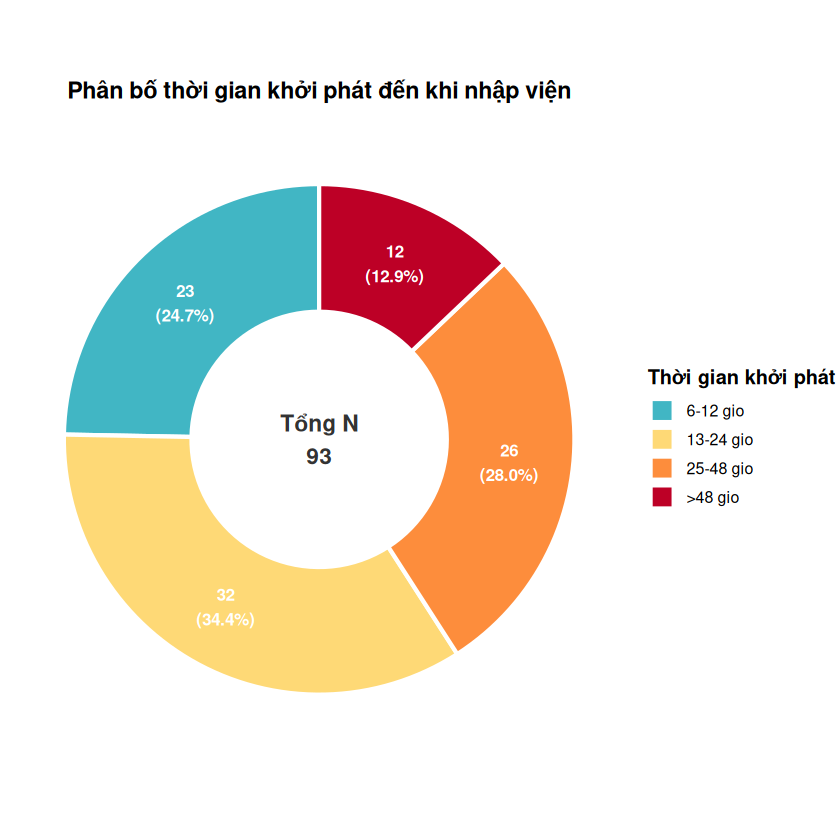

In [46]:
# 1. Nạp thư viện
library(dplyr)
library(ggplot2)

# 2. Đọc dữ liệu
df <- read.csv("Data_viem_tuy_cap.csv")

# 3. Làm sạch dữ liệu và phân nhóm thời gian khởi phát
df_donut <- df %>%
  mutate(gio_khoi_phat = as.numeric(gio_khoi_phat)) %>%
  filter(!is.na(gio_khoi_phat)) %>%
  mutate(
    nhom_gio = cut(
      gio_khoi_phat,
      breaks = c(-Inf, 5.99, 12, 24, 48, Inf),
      labels = c("<6 gio", "6-12 gio", "13-24 gio", "25-48 gio", ">48 gio"),
      right = TRUE
    )
  ) %>%
  count(nhom_gio, name = "n") %>%
  mutate(
    pct = round(n / sum(n) * 100, 1),
    # Nhãn hiển thị gồm số lượng và tỷ lệ %
    label_text = sprintf("%d\n(%.1f%%)", n, pct)
  )

# 4. Vẽ biểu đồ Donut
p_donut <- ggplot(df_donut, aes(x = 2, y = pct, fill = nhom_gio)) +
  geom_col(color = "white", linewidth = 1.2, width = 1) +
  coord_polar(theta = "y", start = 0) +
  xlim(0.5, 2.5) +  # Tạo khoảng trống ở giữa để thành hình Donut
  geom_text(
    aes(label = label_text),
    position = position_stack(vjust = 0.5),
    size = 3.6,
    fontface = "bold",
    color = "white"
  ) +
  # Hiển thị tổng số ca ở trung tâm
  annotate(
    "text", x = 0.5, y = 0,
    label = paste0("Tổng N\n", sum(df_donut$n)),
    size = 4.8, fontface = "bold", color = "gray20"
  ) +
  scale_fill_manual(
    values = c(
      "<6 gio"    = "#2b5c8f", 
      "6-12 gio"  = "#41b6c4", 
      "13-24 gio" = "#fed976", 
      "25-48 gio" = "#fd8d3c", 
      ">48 gio"   = "#bd0026"
    ),
    name = "Thời gian khởi phát"
  ) +
  labs(
    title = "Phân bố thời gian khởi phát đến khi nhập viện",
    x = NULL,
    y = NULL
  ) +
  theme_void(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 14, margin = margin(b = 10)),
    legend.position = "right",
    legend.title = element_text(face = "bold")
  )

# Hiển thị biểu đồ
p_donut